# Industry Project: House Price Prediction (Regression, Production-Style)

> **Who is this notebook for?** Beginners who want to see how a **regression** model (predicting a *number*) is built in a real company.
> No math needed. Every step is explained in plain English and the code is heavily commented.

---

### How this notebook is different from `01_linear_regression.ipynb`

| `01_linear_regression.ipynb` | This notebook |
|---|---|
| Derives gradient descent and the normal equation | Uses the libraries directly, the way engineers do at work |
| Synthetic 1-feature data | A real dataset (California housing, ~20k districts) |
| Reports R² | Reports errors **in dollars**, by **segment**, with **uncertainty ranges** |

### The business problem

You work for a real-estate platform (like Zillow). For each neighbourhood, the app shows an **estimated house value**.

- If the estimate is badly wrong, users lose trust.
- The product team also wants a **range** ("between $180k and $240k"), not just one number.

**Your job:** build a model that predicts the median house value of a district, report how wrong it typically is in **dollars**, and give a **prediction interval**.

### Table of Contents
1. Setup and config
2. Load the data and understand the target
3. Clean the data and remove capped values
4. Split the data
5. Feature engineering inside a pipeline
6. Baselines: what does "good" look like?
7. Compare models with cross-validation
8. Predict the log of the price (a classic industry trick)
9. Final test evaluation in dollars
10. Error analysis: where is the model wrong?
11. Prediction intervals: give a range, not just a number
12. Save, load and serve
13. Sanity tests
14. Summary

---
## 1. Setup and config
All settings in one place, a fixed random seed for reproducibility, and logging instead of `print` for status messages.

In [1]:
import json                               # save metadata in a human-readable format
import logging                            # timestamped status messages
import tempfile                           # temporary folder for saved artifacts
import warnings
from dataclasses import dataclass
from pathlib import Path

import joblib                             # save/load the trained pipeline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("house_prices")


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    test_size: float = 0.2
    cv_folds: int = 5
    price_unit_usd: int = 100_000     # the dataset stores prices in units of $100,000
    interval_coverage: float = 0.80   # our price range should contain the true price 80% of the time


CFG = Config()
print(CFG)

Config(random_state=42, test_size=0.2, cv_folds=5, price_unit_usd=100000, interval_coverage=0.8)


---
## 2. Load the data and understand the target

`fetch_california_housing` downloads a real dataset from the 1990 US census (about 400 KB, cached after the first run).
Each row is a **district** (block group) with:

| Column | Meaning |
|---|---|
| `MedInc` | median income of households (in $10,000s) |
| `HouseAge` | median age of the houses |
| `AveRooms`, `AveBedrms` | average rooms / bedrooms per household |
| `Population`, `AveOccup` | number of people, average people per household |
| `Latitude`, `Longitude` | location |
| `MedHouseVal` | **target**: median house value (in $100,000s) |

In [2]:
housing = fetch_california_housing(as_frame=True)     # as_frame=True gives a pandas DataFrame
df = housing.frame.copy()
TARGET = "MedHouseVal"

print(f"{df.shape[0]:,} districts x {df.shape[1]} columns")
print("Missing values:", int(df.isna().sum().sum()))
df.describe().T.round(2)

20,640 districts x 9 columns
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


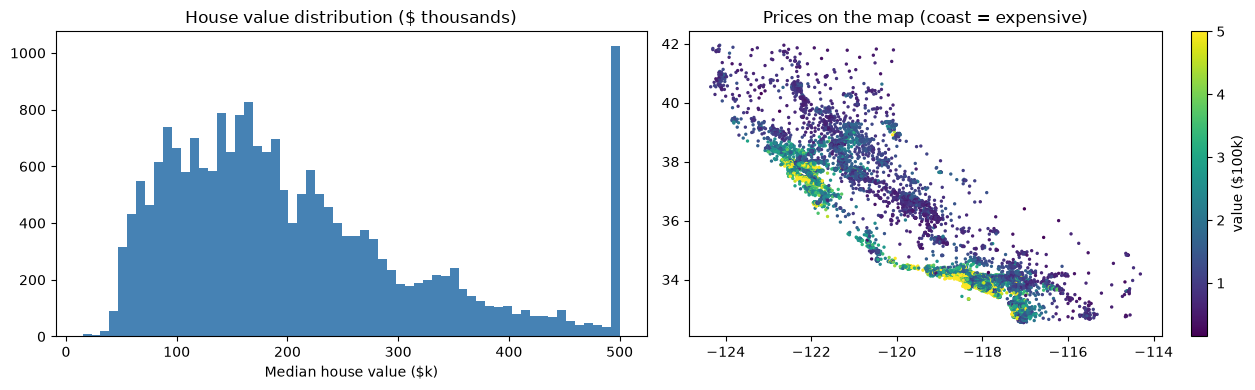

4.8% of districts have the value exactly at the maximum 5.0 ($500k): the census CAPPED them.


In [3]:
# Always LOOK at the target. Two things to notice:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df[TARGET] * CFG.price_unit_usd / 1000, bins=60, color="steelblue")
axes[0].set_title("House value distribution ($ thousands)")
axes[0].set_xlabel("Median house value ($k)")
sc = axes[1].scatter(df["Longitude"], df["Latitude"], c=df[TARGET], s=2, cmap="viridis")
axes[1].set_title("Prices on the map (coast = expensive)")
plt.colorbar(sc, ax=axes[1], label="value ($100k)")
plt.tight_layout(); plt.show()

capped = (df[TARGET] >= 5.0).mean()
print(f"{capped:.1%} of districts have the value exactly at the maximum 5.0 ($500k): the census CAPPED them.")

**Two real-world data problems found just by plotting:**
1. **Right-skewed target**: many cheap districts, few very expensive ones. Models struggle with this, and we'll fix it in Section 8.
2. **Capped values**: every price above $500k was recorded as exactly $500k. The model cannot learn the real price of those houses from this data.

In industry, these discoveries happen in the **EDA** (Exploratory Data Analysis) stage, and they change the whole project.

---
## 3. Clean the data and remove capped values

Capped rows teach the model a **wrong** target ("this mansion costs $500k"). The honest options are:
- remove them and **document** that the model is only valid below $500k, or
- use special "censored regression" models (see `08_generalized_linear_models.ipynb`, Tobit model).

We take the first, more common, option. We also remove a few rows with impossible occupancy (data entry errors).

In [4]:
def clean_housing(data: pd.DataFrame) -> pd.DataFrame:
    """Remove rows that would teach the model wrong things. Log every decision."""
    data = data.copy()
    n0 = len(data)
    data = data[data[TARGET] < 5.0]                       # drop capped targets
    log.info("Removed %d capped-price rows", n0 - len(data))
    n1 = len(data)
    data = data[(data["AveOccup"] < 20) & (data["AveRooms"] < 50)]   # >20 people per home = error
    log.info("Removed %d rows with impossible occupancy/rooms", n1 - len(data))
    return data.reset_index(drop=True)


df_clean = clean_housing(df)
print(f"Rows kept: {len(df_clean):,} of {len(df):,}")

2026-10-21 15:56:26,128 | INFO | Removed 992 capped-price rows


2026-10-21 15:56:26,130 | INFO | Removed 17 rows with impossible occupancy/rooms


Rows kept: 19,631 of 20,640


---
## 4. Split the data
80% training (with cross-validation inside), 20% locked test set used **once**.

**Industry trick (from Aurélien Géron's *Hands-On Machine Learning*, a classic for this exact dataset):** income is the strongest driver of price, so we make sure both sets contain the same mix of low/medium/high-income districts. We bucket income into 5 categories and **stratify** on them, just like `stratify=y` in classification.

In [5]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]
income_category = pd.cut(X["MedInc"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1, 2, 3, 4, 5])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CFG.test_size, stratify=income_category, random_state=CFG.random_state)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")

# Check: the income mix is the same in both sets
pd.DataFrame({"train %": income_category[X_train.index].value_counts(normalize=True).sort_index() * 100,
              "test %": income_category[X_test.index].value_counts(normalize=True).sort_index() * 100}).round(1)

Train: 15,704 | Test: 3,927


,train %,test %
MedInc,,
1,4.1,4.1
2,33.3,33.3
3,36.1,36.1
4,17.8,17.8
5,8.7,8.7


---
## 5. Feature engineering inside a pipeline

Domain knowledge beats fancy algorithms. Real-estate experts know that:
- **rooms per person** says more than rooms alone,
- **bedroom ratio** (bedrooms / rooms) separates apartments from family homes,
- **distance to big cities** drives prices (LA and San Francisco).

We write this as a plain function and wrap it in `FunctionTransformer`, so it becomes a pipeline step. That way the *exact same* features are computed at training time and in the app.

In [6]:
CITY_CENTERS = {"los_angeles": (34.05, -118.24), "san_francisco": (37.77, -122.42)}


def add_housing_features(data: pd.DataFrame) -> pd.DataFrame:
    """Create domain features. Pure function: same input -> same output, no hidden state."""
    data = data.copy()
    data["rooms_per_person"] = data["AveRooms"] / data["AveOccup"]
    data["bedroom_ratio"] = data["AveBedrms"] / data["AveRooms"]
    data["log_population"] = np.log1p(data["Population"])        # log tames big numbers
    for city, (lat, lon) in CITY_CENTERS.items():
        # Approximate distance in km (1 degree ≈ 111 km), good enough for a feature
        data[f"km_to_{city}"] = 111 * np.sqrt((data["Latitude"] - lat) ** 2 + (data["Longitude"] - lon) ** 2)
    return data


feature_step = FunctionTransformer(add_housing_features)   # turns the function into a pipeline step
feature_step.fit_transform(X_train).head(3).round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,rooms_per_person,bedroom_ratio,log_population,km_to_los_angeles,km_to_san_francisco
15291,3.52,42.0,4.79,1.04,1211.0,2.96,37.71,-122.47,1.62,0.22,7.10,620.89,8.67
5522,3.02,25.0,4.07,1.09,2205.0,2.97,34.15,-118.27,1.37,0.27,7.70,11.59,611.28
9034,2.78,31.0,5.16,1.01,327.0,4.04,39.10,-123.16,1.28,0.20,5.79,782.60,168.94


---
## 6. Baselines: what does "good" look like?

**MAE (Mean Absolute Error)** is the metric managers understand: *"on average, our estimate is off by $X"*.
We'll always convert errors back into **dollars**.

Baseline 1: predict the **average price** for everyone (`DummyRegressor`).
Baseline 2: a **linear model** (`RidgeCV` = linear regression with automatic regularisation strength).

In [7]:
cv = KFold(n_splits=CFG.cv_folds, shuffle=True, random_state=CFG.random_state)
SCORING = {"mae": "neg_mean_absolute_error", "r2": "r2"}   # sklearn maximises, so MAE is negated


def make_pipeline(model, scale: bool = True) -> Pipeline:
    steps = [("features", feature_step)]
    if scale:                                      # linear models need scaling; trees don't care
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


def cv_report(name: str, pipeline) -> dict:
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    mae_usd = -scores["test_mae"] * CFG.price_unit_usd             # back to dollars
    return {"model": name,
            "MAE ($)": f"{mae_usd.mean():,.0f} ± {mae_usd.std():,.0f}",
            "R²": f"{scores['test_r2'].mean():.3f}"}


results = [
    cv_report("Dummy (always the mean)", make_pipeline(DummyRegressor())),
    cv_report("Ridge (linear)", make_pipeline(RidgeCV(alphas=np.logspace(-3, 3, 13)))),
]
pd.DataFrame(results)

,model,MAE ($),R²
0,Dummy (always the mean),"78,121 ± 887",-0.001
1,Ridge (linear),"42,828 ± 778",0.639


---
## 7. Compare models with cross-validation
Tree ensembles capture **non-linear** effects (e.g. "near the coast AND high income" → very expensive) that a straight line cannot.

> **Industry note, spatial leakage:** neighbouring districts have very similar prices. With a random split, the model may be tested on a district whose next-door neighbour was in training, which makes scores look a bit better than they will be for a brand-new area. Teams that need a strict estimate use `GroupKFold` with groups = map grid cells, so whole areas are held out together.

In [8]:
results += [
    cv_report("Random Forest", make_pipeline(
        RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1,
                              random_state=CFG.random_state), scale=False)),
    cv_report("HistGradientBoosting", make_pipeline(
        HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08,
                                      random_state=CFG.random_state), scale=False)),
]
pd.DataFrame(results)

,model,MAE ($),R²
0,Dummy (always the mean),"78,121 ± 887",-0.001
1,Ridge (linear),"42,828 ± 778",0.639
2,Random Forest,"29,183 ± 498",0.792
3,HistGradientBoosting,"27,533 ± 628",0.820


---
## 8. Predict the log of the price (a classic industry trick)

Prices are skewed: a $50k error on a $100k house is terrible, but on a $450k house it's acceptable.
If we train on `log(price)`, the model focuses on **relative** (percentage) errors, which is what users actually feel.

`TransformedTargetRegressor` does this cleanly: it applies `log` before training and `exp` after predicting, so **callers still get prices in normal units**. You never have to remember to convert back.

In [9]:
log_target_model = TransformedTargetRegressor(
    regressor=make_pipeline(HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08,
                                                          random_state=CFG.random_state), scale=False),
    func=np.log1p,              # applied to y before fitting
    inverse_func=np.expm1,      # applied to predictions automatically
)
results.append(cv_report("HistGB + log target", log_target_model))
pd.DataFrame(results)

,model,MAE ($),R²
0,Dummy (always the mean),"78,121 ± 887",-0.001
1,Ridge (linear),"42,828 ± 778",0.639
2,Random Forest,"29,183 ± 498",0.792
3,HistGradientBoosting,"27,533 ± 628",0.820
4,HistGB + log target,"27,163 ± 561",0.818


Compare the last two rows. If the log version is better or equal, we keep it: it is also better behaved for cheap houses (it can never predict a negative price!).

---
## 9. Final test evaluation in dollars
Train on all training data, evaluate **once** on the test set, and report in business language.

In [10]:
final_model = log_target_model.fit(X_train, y_train)
pred_test = final_model.predict(X_test)

mae_usd = mean_absolute_error(y_test, pred_test) * CFG.price_unit_usd
mape = mean_absolute_percentage_error(y_test, pred_test)
within_10pct = np.mean(np.abs(pred_test - y_test) / y_test <= 0.10)

test_metrics = {"MAE_usd": round(mae_usd), "MAPE": round(mape, 4), "R2": round(r2_score(y_test, pred_test), 4),
                "share_within_10pct": round(within_10pct, 4)}
print(json.dumps(test_metrics, indent=2))
print(f"\nIn plain English: on average the estimate is off by about ${mae_usd:,.0f} "
      f"({mape:.0%}), and {within_10pct:.0%} of estimates are within 10% of the true value.")

{
  "MAE_usd": 26025,
  "MAPE": 0.1467,
  "R2": 0.8372,
  "share_within_10pct": 0.4866
}

In plain English: on average the estimate is off by about $26,025 (15%), and 49% of estimates are within 10% of the true value.


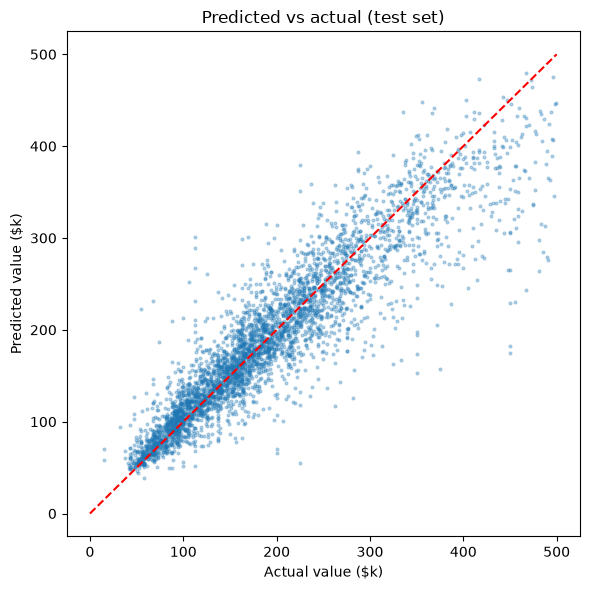

In [11]:
# Predicted vs actual: points on the red line are perfect predictions
plt.figure(figsize=(6, 6))
plt.scatter(y_test * 100, pred_test * 100, s=4, alpha=0.3)
plt.plot([0, 500], [0, 500], "r--")
plt.xlabel("Actual value ($k)"); plt.ylabel("Predicted value ($k)")
plt.title("Predicted vs actual (test set)")
plt.tight_layout(); plt.show()

---
## 10. Error analysis: where is the model wrong?

One average number hides problems. **Error analysis** slices the errors by segment.
Product teams care a lot about this: if the model is great in cities but terrible in rural areas, rural users will leave.

In [12]:
analysis = X_test.copy()
analysis["actual"] = y_test.values
analysis["predicted"] = pred_test
analysis["abs_error_usd"] = (analysis["actual"] - analysis["predicted"]).abs() * CFG.price_unit_usd
analysis["pct_error"] = (analysis["actual"] - analysis["predicted"]).abs() / analysis["actual"]

# Segment 1: by price band (are expensive or cheap homes harder?)
analysis["price_band"] = pd.cut(analysis["actual"] * 100, [0, 100, 200, 300, 400, 500],
                                labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k"])
# Segment 2: by income band
analysis["income_band"] = pd.qcut(analysis["MedInc"], 4, labels=["low", "mid-low", "mid-high", "high"])

for segment in ["price_band", "income_band"]:
    summary = analysis.groupby(segment, observed=True).agg(
        districts=("actual", "size"),
        MAE_usd=("abs_error_usd", "mean"),
        median_pct_error=("pct_error", "median"),
    ).round({"MAE_usd": 0, "median_pct_error": 3})
    print(f"\nErrors by {segment}:")
    print(summary)


Errors by price_band:
            districts  MAE_usd  median_pct_error
price_band                                      
<100k             744  14520.0             0.125
100-200k         1652  21045.0             0.104
200-300k          983  29058.0             0.091
300-400k          396  39443.0             0.084
400-500k          152  81883.0             0.149

Errors by income_band:
             districts  MAE_usd  median_pct_error
income_band                                      
low                982  20903.0             0.121
mid-low            983  25365.0             0.113
mid-high           980  25753.0             0.094
high               982  32078.0             0.090


**Typical findings (and what a team would do about them):**
- Dollar errors grow with price (a 10% miss on a $450k home is $45k).
- *Percentage* errors are highest at the **two extremes**: the cheapest homes, and the $400-500k band right below the $500k cap, where there are few training examples → show a wider range there, or warn users.
- Segments with few examples have unstable errors → collect more data there.

---
## 11. Prediction intervals: give a range, not just a number

A single number hides uncertainty. We train two extra models using **quantile loss**:
- one predicts the **10th percentile** (a "low" estimate),
- one predicts the **90th percentile** (a "high" estimate).

Together they *should* give an **80% range**. We then **check** on the test set how often the real price falls inside. Always verify uncertainty claims!

We set aside 20% of the training data as a **calibration set**. We don't need it yet, but Step 11b will use it.

In [13]:
low_q = (1 - CFG.interval_coverage) / 2            # 0.10
high_q = 1 - low_q                                 # 0.90


# Split the TRAINING data again: 80% to fit the quantile models, 20% to calibrate them (Step 11b)
X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train, test_size=0.2,
                                                  random_state=CFG.random_state)


def quantile_model(q: float):
    return make_pipeline(HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=400,
                                                       learning_rate=0.08, random_state=CFG.random_state),
                         scale=False).fit(X_fit, y_fit)


lower_model, upper_model = quantile_model(low_q), quantile_model(high_q)
raw_lower, raw_upper = lower_model.predict(X_test), upper_model.predict(X_test)

raw_coverage = np.mean((y_test >= raw_lower) & (y_test <= raw_upper))
print(f"Target coverage: {CFG.interval_coverage:.0%} | Actual coverage on test: {raw_coverage:.1%}")
print(f"Ranges where low > high ('crossing quantiles', should be ~0): {np.mean(raw_lower > raw_upper):.1%}")

Target coverage: 80% | Actual coverage on test: 69.7%
Ranges where low > high ('crossing quantiles', should be ~0): 0.0%


### 11b. The ranges are too narrow, so calibrate them (conformal prediction)

The raw quantile models usually cover **less** than promised: they are over-confident on new data. (The official scikit-learn example on gradient-boosting prediction intervals shows the same effect.) Shipping a range that claims 80% but delivers ~72% would quietly mislead users.

The industry fix is **conformalized quantile regression (CQR)**, which takes only a few lines:
1. On the **calibration set** (data the quantile models never saw), measure how far each true price falls **outside** its range (negative if inside).
2. Take the 80th percentile of those misses, `q`.
3. Widen every future range by `q` on both sides.

This comes with a mathematical guarantee: on new data similar to the calibration data, coverage will be at least 80%. See `../14_conformal_prediction/01_conformal_prediction.ipynb` for the theory.

In [14]:
calib_low, calib_high = lower_model.predict(X_calib), upper_model.predict(X_calib)
# How far outside the range is each true price? (positive = outside, negative = safely inside)
misses = np.maximum(calib_low - y_calib.values, y_calib.values - calib_high)
n = len(misses)
conformal_q = float(np.quantile(misses, min(1.0, np.ceil((n + 1) * CFG.interval_coverage) / n)))

lower, upper = raw_lower - conformal_q, raw_upper + conformal_q      # calibrated ranges
coverage = np.mean((y_test >= lower) & (y_test <= upper))
avg_width_usd = np.mean(upper - lower) * CFG.price_unit_usd

print(f"Correction q = {conformal_q * CFG.price_unit_usd:+,.0f} $ on each side")
print(f"Coverage on test: raw {raw_coverage:.1%}  ->  calibrated {coverage:.1%} (target {CFG.interval_coverage:.0%})")
print(f"Average range width: ${avg_width_usd:,.0f}")

# Show 5 example districts the way the app would
examples = pd.DataFrame({
    "estimate": (pred_test[:5] * 100).round(0), "low": (lower[:5] * 100).round(0),
    "high": (upper[:5] * 100).round(0), "actual": (y_test.values[:5] * 100).round(0)})
print("\nApp display, in $ thousands:")
examples

Correction q = +6,481 $ on each side
Coverage on test: raw 69.7%  ->  calibrated 80.0% (target 80%)
Average range width: $89,907

App display, in $ thousands:


,estimate,low,high,actual
0,134.0,119.0,176.0,133.0
1,241.0,196.0,310.0,292.0
2,166.0,141.0,294.0,225.0
3,205.0,179.0,258.0,221.0
4,384.0,251.0,438.0,352.0


---
## 12. Save, load and serve
We bundle the three models (estimate, low, high) and their metadata, then load them back exactly as an application would.

In [15]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="house_price_model_"))
bundle = {"point": final_model, "lower": lower_model, "upper": upper_model,
          "conformal_q": conformal_q}            # the calibration correction must be saved too!
joblib.dump(bundle, ARTIFACT_DIR / "house_price_models.joblib")
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps({
    "model_name": "house_price_estimator", "model_version": "1.0.0",
    "sklearn_version": sklearn.__version__, "input_columns": list(X_train.columns),
    "valid_range_usd": [0, 500_000],          # documented limitation from Section 3!
    "interval_coverage": CFG.interval_coverage, "test_metrics": test_metrics,
}, indent=2))


class PriceEstimator:
    """What the web app would import. Loads once, predicts many times."""

    def __init__(self, artifact_dir: Path):
        self.models = joblib.load(artifact_dir / "house_price_models.joblib")
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())

    def estimate(self, district: dict) -> dict:
        missing = set(self.meta["input_columns"]) - set(district)
        if missing:                                   # fail fast with a helpful message
            raise ValueError(f"Missing fields: {sorted(missing)}")
        row = pd.DataFrame([district])[self.meta["input_columns"]]
        q = self.models["conformal_q"]
        predict = lambda m: float(self.models[m].predict(row)[0])
        to_usd = lambda value: int(round(value * CFG.price_unit_usd, -3))     # rounded to $1,000
        low, point, high = to_usd(predict("lower") - q), to_usd(predict("point")), to_usd(predict("upper") + q)
        return {"estimate_usd": point, "range_usd": [min(low, point), max(high, point)],
                "note": "Model valid only for values below $500k"}


app_model = PriceEstimator(ARTIFACT_DIR)
example_district = X_test.iloc[0].to_dict()
print(example_district)
print(app_model.estimate(example_district))

{'MedInc': 4.2647, 'HouseAge': 26.0, 'AveRooms': 5.943462897526501, 'AveBedrms': 1.0070671378091873, 'Population': 1806.0, 'AveOccup': 3.1908127208480566, 'Latitude': 38.0, 'Longitude': -121.85}
{'estimate_usd': 134000, 'range_usd': [119000, 176000], 'note': 'Model valid only for values below $500k'}


---
## 13. Sanity tests
Small automated checks that would run in CI before any new model version is deployed.

In [16]:
def test_no_negative_prices():
    assert (final_model.predict(X_test) > 0).all()


def test_income_increases_price():
    """Behavioural test: richer neighbourhood, everything else equal, should not be cheaper."""
    row = X_test.iloc[[0]].copy()
    poorer = final_model.predict(row.assign(MedInc=2.0))[0]
    richer = final_model.predict(row.assign(MedInc=8.0))[0]
    assert richer > poorer


def test_quality_gate():
    assert test_metrics["MAE_usd"] < 40_000, "Model too inaccurate to ship"


def test_interval_coverage_close_to_target():
    """Calibrated ranges must deliver (about) the promised coverage."""
    assert abs(coverage - CFG.interval_coverage) < 0.03, f"coverage {coverage:.1%}"


for test in [test_no_negative_prices, test_income_increases_price, test_quality_gate,
             test_interval_coverage_close_to_target]:
    test()
    print("PASSED ", test.__name__)

PASSED  test_no_negative_prices
PASSED  test_income_increases_price
PASSED  test_quality_gate
PASSED  test_interval_coverage_close_to_target


---
## 14. Summary

| Industry practice | Where we used it |
|---|---|
| Look at the target before modelling | Found skew and the $500k cap |
| Document data limitations | `valid_range_usd` in the metadata |
| Domain features inside the pipeline | `add_housing_features` + `FunctionTransformer` |
| Baselines + cross-validation | Dummy, Ridge, RF, HistGB |
| Log-target trick | `TransformedTargetRegressor` |
| Business metrics | MAE in dollars, % within 10% |
| Error analysis by segment | Price and income bands |
| Stratified split for regression | Income categories, as in Géron's *Hands-On ML* |
| Uncertainty | Quantile models + coverage check + **conformal calibration** |
| Serving + tests | `PriceEstimator` class + behavioural tests |

### Practice exercises
1. Add a feature `income_per_room = MedInc / AveRooms`. Does the CV MAE improve?
2. Change `interval_coverage` to `0.90`. How much wider do the ranges become? Is the raw (un-calibrated) coverage still too low?
3. Try `lightgbm.LGBMRegressor` inside `TransformedTargetRegressor`.

### Related notebooks
- Theory: `01_linear_regression.ipynb`, `04_ensemble_methods.ipynb`
- Uncertainty with guarantees: `../14_conformal_prediction/01_conformal_prediction.ipynb`
- Classification version of this workflow: `14_industry_churn_prediction.ipynb`